In [8]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [9]:
import sys; print(sys.executable)

c:\Users\pauum\Desktop\PAULA\uni\MASTER\TFM\CRYOEM\Proyecto\.venv\Scripts\python.exe


In [10]:
from pathlib import Path
import tifffile as tiff

DATA_DIR = Path(r"C:\Users\pauum\Desktop\PAULA\uni\MASTER\TFM\CRYOEM\Proyecto\datos")
tif_path = DATA_DIR / "annotations0-data0.tif"   

volume = tiff.imread(tif_path)
# If the default path doesn't exist, try auto-detection in dataset/
if not tif_path.exists():
    candidates = sorted(Path("../datos").glob("*.tif")) + sorted(Path("dataset").glob("*.tiff"))
    if len(candidates) == 0:
        raise FileNotFoundError(
            "No .tif/.tiff file found in dataset/. Set `tif_path` to your file path."
        )
    tif_path = candidates[0]
    print(f"Using detected TIFF file: {tif_path}")

volume = tiff.imread(tif_path)

# Ensure volume is (z, y, x) for slice-wise processing
if volume.ndim == 2:
    volume = volume[np.newaxis, ...]  # single image -> 1-slice volume
elif volume.ndim > 3:
    raise ValueError(f"Expected 2D/3D TIFF stack, got shape {volume.shape}")

print(f"Loaded TIFF: {tif_path}")
print(f"Volume shape (z, y, x): {volume.shape}")
print(f"dtype: {volume.dtype}")

Loaded TIFF: C:\Users\pauum\Desktop\PAULA\uni\MASTER\TFM\CRYOEM\Proyecto\datos\annotations0-data0.tif
Volume shape (z, y, x): (200, 512, 512)
dtype: float32


In [11]:
# Keep only slices that contain information (not fully uniform)
v = volume.astype(np.float32)

slice_min = v.min(axis=(1, 2))
slice_max = v.max(axis=(1, 2))
slice_std = v.std(axis=(1, 2))

range_eps = 1e-6
std_eps = 1e-6

valid_indices = np.where(((slice_max - slice_min) > range_eps) & (slice_std > std_eps))[0]
volume_filtered = volume[valid_indices]  # original slice values are unchanged

print(f"Kept {len(valid_indices)}/{volume.shape[0]} informative slices")
print(f"Filtered volume shape: {volume_filtered.shape}")

Kept 72/200 informative slices
Filtered volume shape: (72, 512, 512)


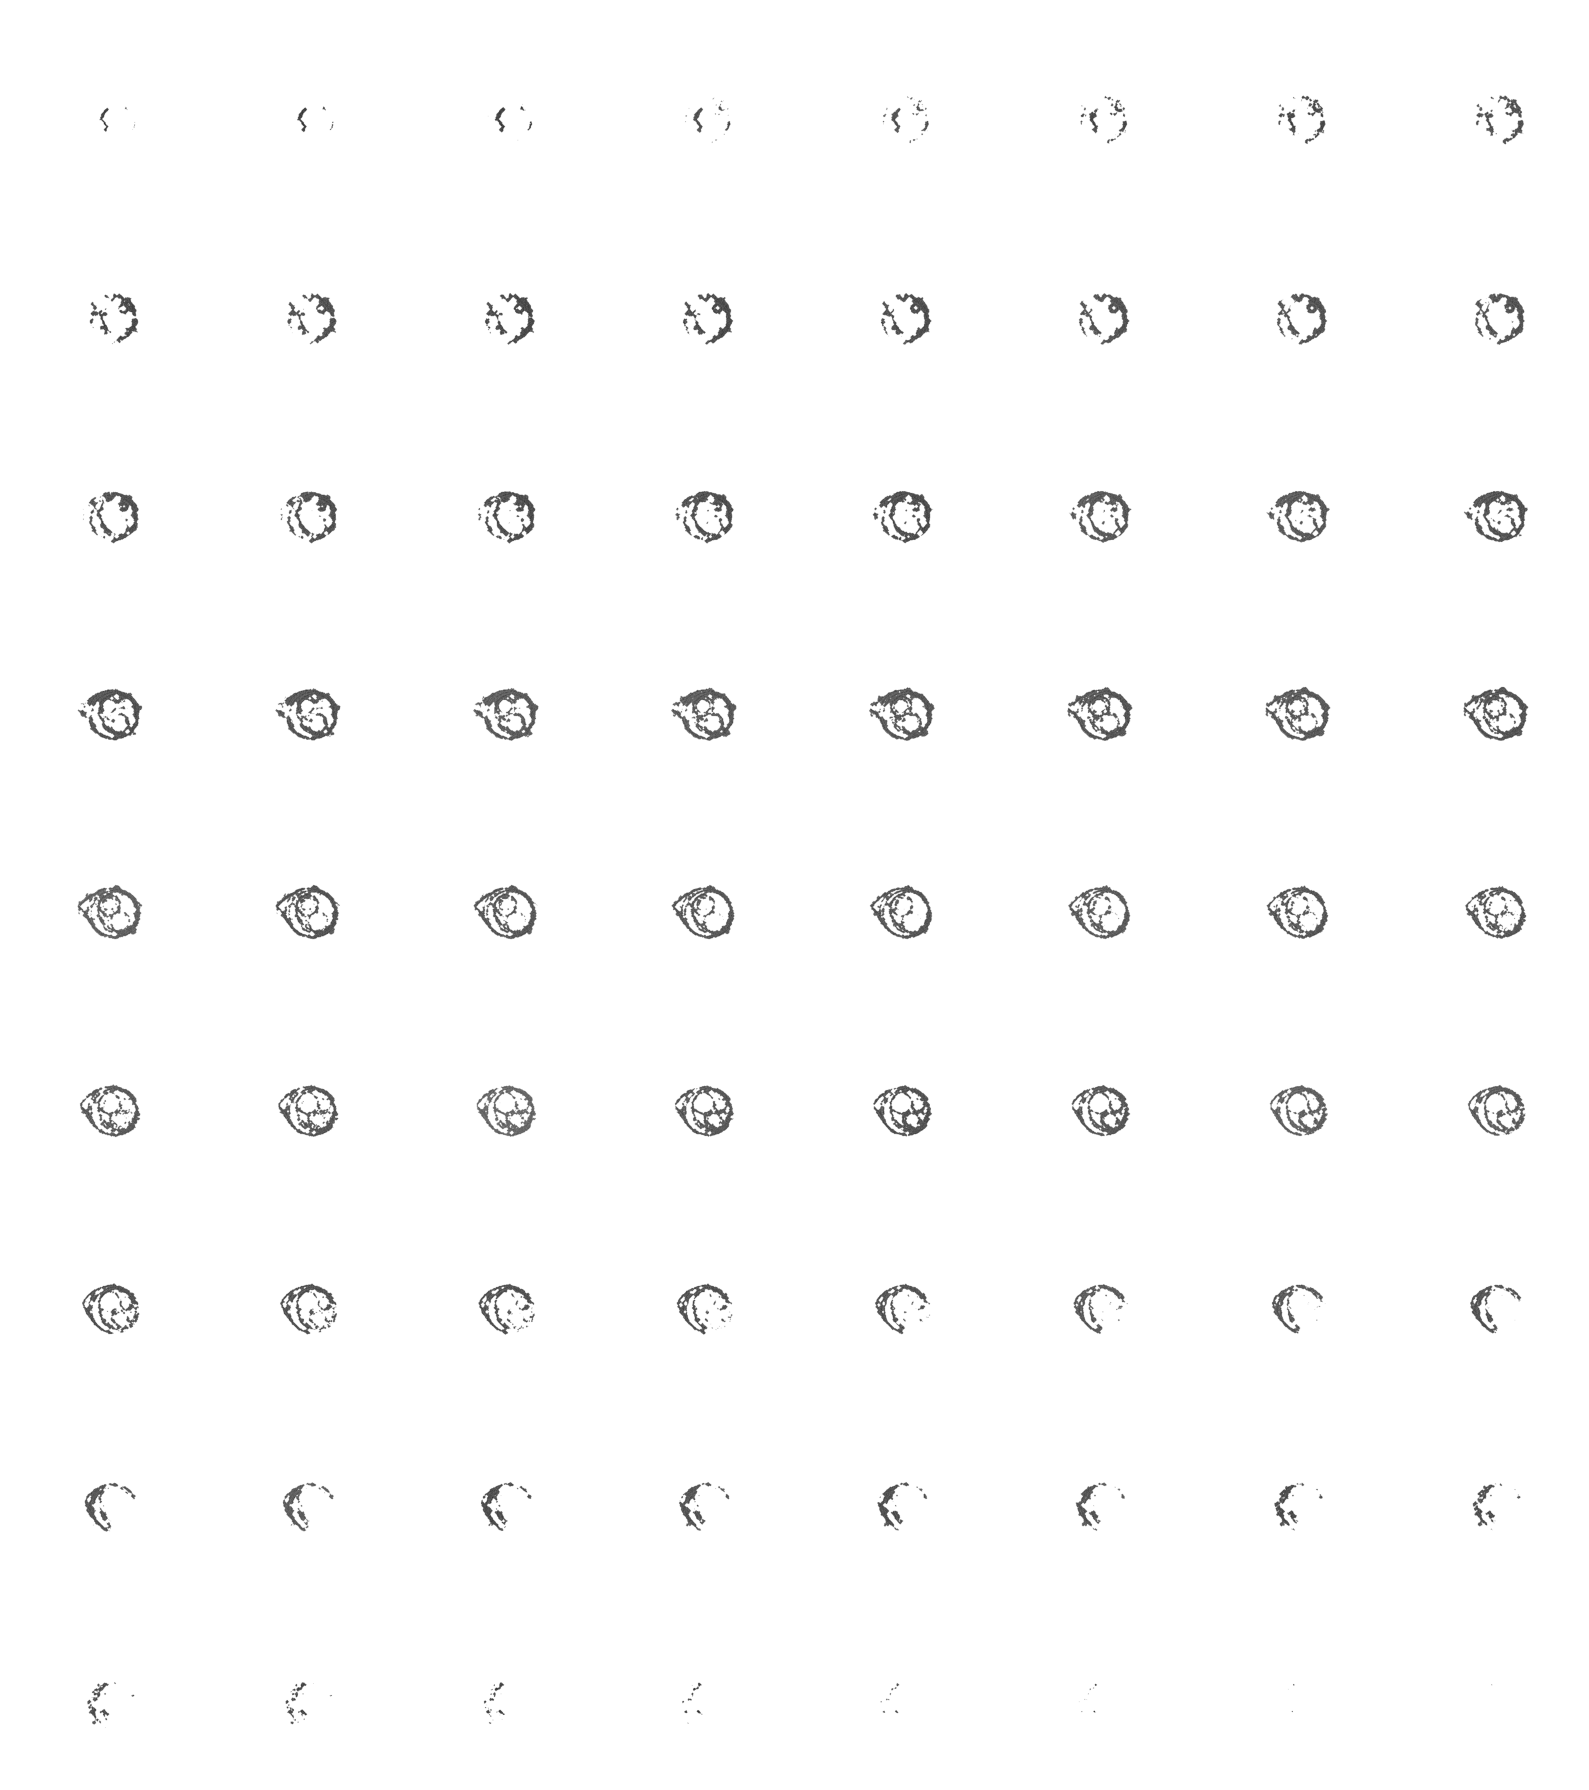

In [12]:
# Plot only the informative (remaining) slices
n_slices_filtered = volume_filtered.shape[0]
n_cols = 8
n_rows = int(np.ceil(n_slices_filtered / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows))
axes = np.array(axes).reshape(n_rows, n_cols)

for i in range(n_rows * n_cols):
    r, c = divmod(i, n_cols)
    ax = axes[r, c]
    if i < n_slices_filtered:
        ax.imshow(volume_filtered[i], cmap="gray")
        ax.axis("off")
    else:
        ax.axis("off")

plt.tight_layout()
plt.show()

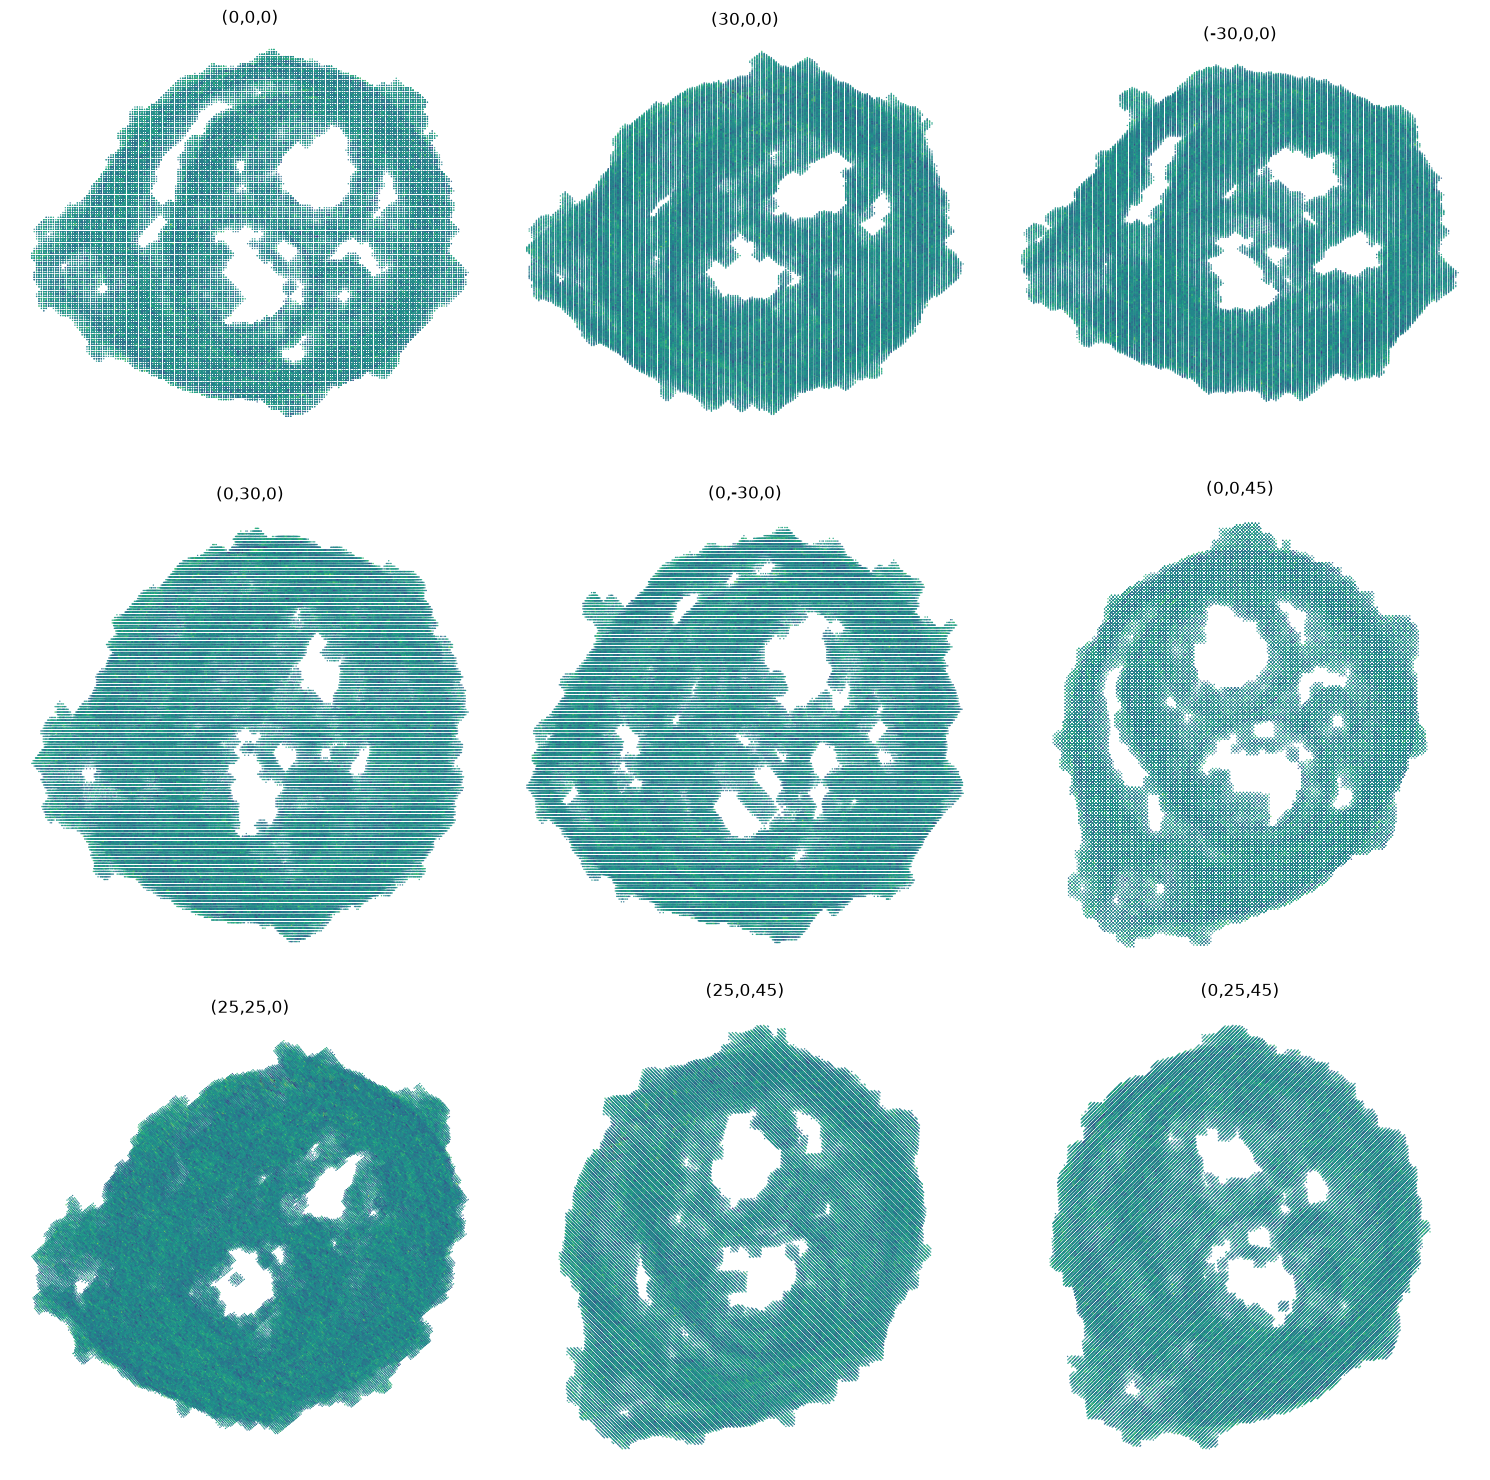

In [13]:
# Use all informative slices directly
vol = volume_filtered.astype(np.float32)

# Background is the constant max value (1.0 here)
bg = vol.max()
eps = 1e-6
mask = vol < (bg - eps)

# Coordinates in filtered volume
zf, y, x = np.where(mask)
vals = vol[mask]

# Map filtered z back to original z-space
z = valid_indices[zf]

# Center coordinates for stable rotations
xc = (x.min() + x.max()) / 2.0
yc = (y.min() + y.max()) / 2.0
zc = (z.min() + z.max()) / 2.0

xx = x - xc
yy = y - yc
zz = z - zc

# 9 viewpoints: (rotX, rotY, rotZ) in degrees
views = [
    ("(0,0,0)", 0, 0, 0),
    ("(30,0,0)", 30, 0, 0),
    ("(-30,0,0)", -30, 0, 0),
    ("(0,30,0)", 0, 30, 0),
    ("(0,-30,0)", 0, -30, 0),
    ("(0,0,45)", 0, 0, 45),
    ("(25,25,0)", 25, 25, 0),
    ("(25,0,45)", 25, 0, 45),
    ("(0,25,45)", 0, 25, 45),
]

fig, axs = plt.subplots(3, 3, figsize=(15, 15))
axs = axs.ravel()

for i, (title, ax_deg, ay_deg, az_deg) in enumerate(views):
    axr = np.deg2rad(ax_deg)
    ayr = np.deg2rad(ay_deg)
    azr = np.deg2rad(az_deg)

    # Rotation matrices
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(axr), -np.sin(axr)],
        [0, np.sin(axr),  np.cos(axr)],
    ])
    Ry = np.array([
        [ np.cos(ayr), 0, np.sin(ayr)],
        [0, 1, 0],
        [-np.sin(ayr), 0, np.cos(ayr)],
    ])
    Rz = np.array([
        [np.cos(azr), -np.sin(azr), 0],
        [np.sin(azr),  np.cos(azr), 0],
        [0, 0, 1],
    ])

    # Combined rotation: X -> Y -> Z
    R = Rz @ Ry @ Rx
    rot = R @ np.vstack((xx, yy, zz))

    # Orthographic projection to 2D
    u = rot[0]
    v = rot[1]

    axs[i].scatter(u, v, c=vals, s=1, cmap="viridis", linewidths=0, alpha=0.9)
    axs[i].set_aspect("equal")
    axs[i].axis("off")
    axs[i].set_title(title)

plt.tight_layout()
plt.show()

Archivo : C:\Users\pauum\Desktop\PAULA\uni\MASTER\TFM\CRYOEM\Proyecto\datos\annotations0-data0.tif
Páginas (slices): 200
Tamaño por página (alto, ancho): (512, 512)
dtype   : float32
Compresión: NONE
Ejes interpretados: QYX -> shape total (200, 512, 512)
shape (z,y,x)=(200, 512, 512)  dtype=float32  min=0.5761  max=1  media=0.9981


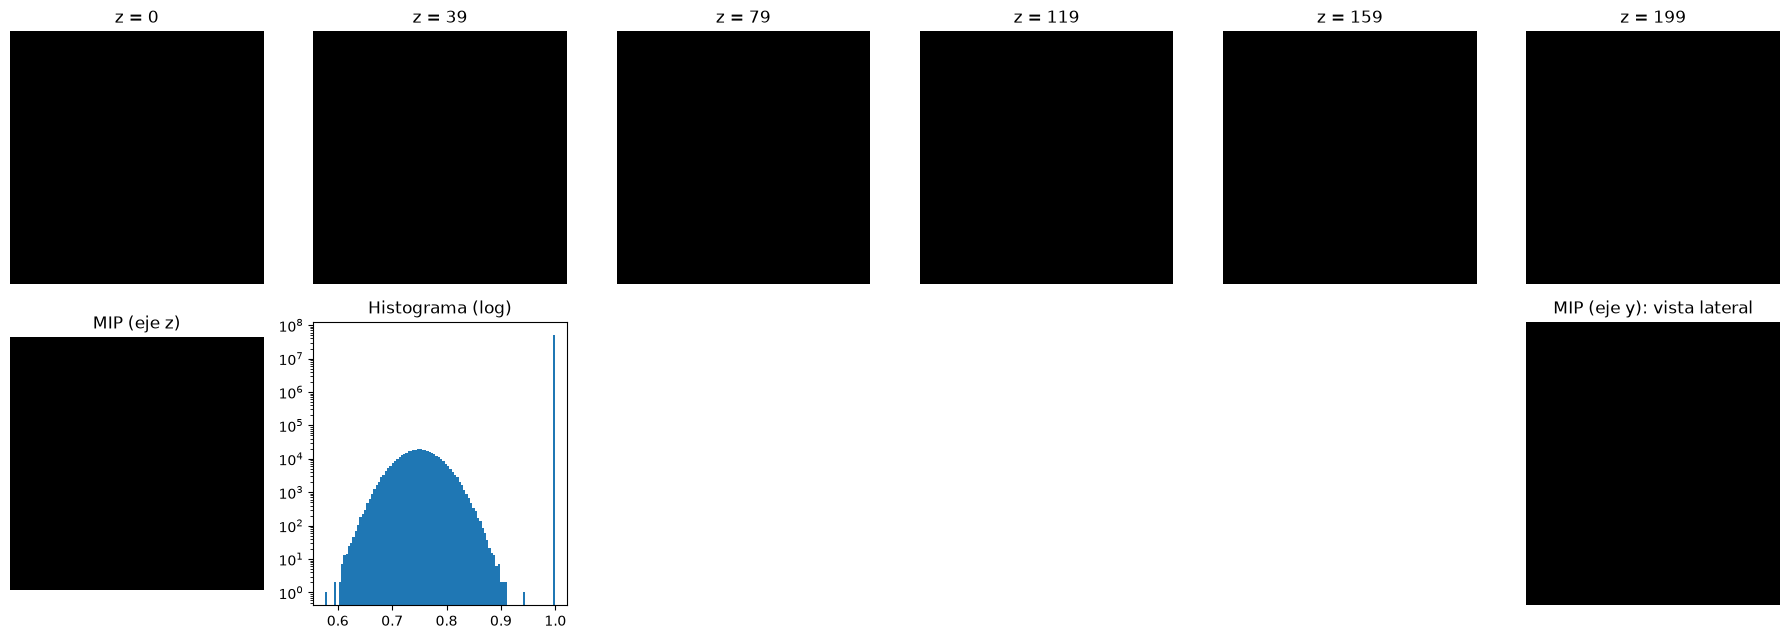

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tifffile as tiff

def inspect_tif(path):
    """Metadatos básicos de un TIFF (sin cargarlo entero)."""
    with tiff.TiffFile(path) as tf:
        print(f"Archivo : {path}")
        print(f"Páginas (slices): {len(tf.pages)}")
        p = tf.pages[0]
        print(f"Tamaño por página (alto, ancho): {p.shape}")
        print(f"dtype   : {p.dtype}")
        print(f"Compresión: {p.compression.name}")
        print(f"Ejes interpretados: {tf.series[0].axes} -> shape total {tf.series[0].shape}")

def show_tif(path, n_slices=6, cmap="gray", pct=(1, 99)):
    """Slices equiespaciados + proyecciones de máxima intensidad + histograma."""
    vol = tiff.imread(path)
    if vol.ndim == 2:
        vol = vol[None]
    elif vol.ndim > 3:
        vol = vol.reshape(-1, *vol.shape[-2:])  # colapsa ejes extra (canales/tiempo)

    vmin, vmax = np.percentile(vol, pct)  # contraste robusto a outliers
    print(f"shape (z,y,x)={vol.shape}  dtype={vol.dtype}  "
          f"min={vol.min():.4g}  max={vol.max():.4g}  media={vol.mean():.4g}")

    idx = np.linspace(0, vol.shape[0] - 1, min(n_slices, vol.shape[0])).astype(int)
    fig, axs = plt.subplots(2, len(idx), figsize=(3 * len(idx), 6.5), squeeze=False)
    for a, i in zip(axs[0], idx):
        a.imshow(vol[i], cmap=cmap, vmin=vmin, vmax=vmax)
        a.set_title(f"z = {i}"); a.axis("off")

    for a in axs[1]:
        a.axis("off")
    axs[1, 0].imshow(vol.max(axis=0), cmap=cmap); axs[1, 0].set_title("MIP (eje z)")
    if len(idx) > 2:
        ax_h = fig.add_subplot(2, len(idx), len(idx) + 2)
        ax_h.hist(vol.ravel(), bins=100, log=True); ax_h.set_title("Histograma (log)")
        axs[1, -1].imshow(vol.max(axis=1), cmap=cmap, aspect="auto")
        axs[1, -1].set_title("MIP (eje y): vista lateral")
    plt.tight_layout(); plt.show()
    return vol

inspect_tif(tif_path)
vol = show_tif(tif_path)

shape=(200, 512, 512) dtype=float32 fondo=1 señal: 0.759% de los vóxeles, rango [0.668, 0.832]


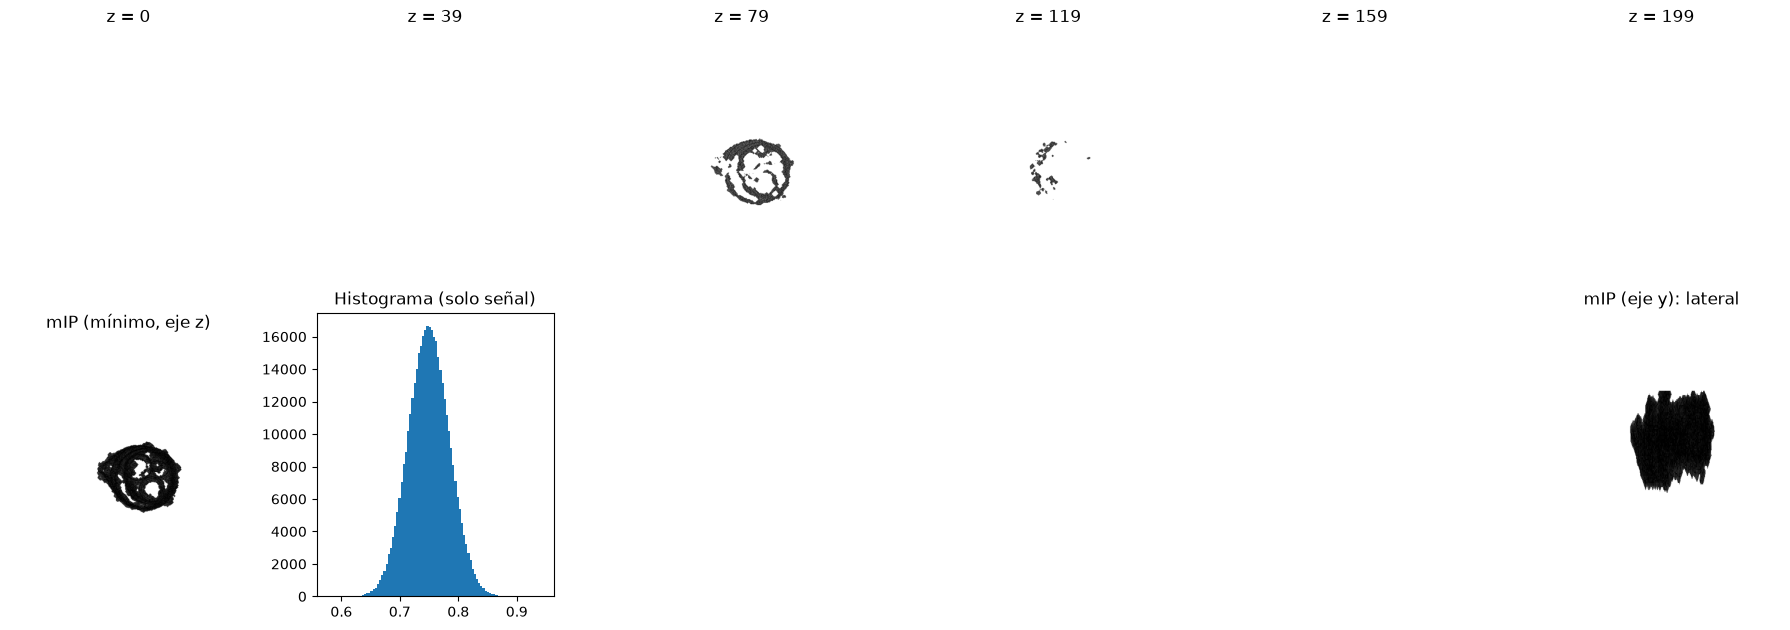

In [15]:
def show_tif(path, n_slices=6, cmap="gray", pct=(1, 99), bg=None):
    vol = tiff.imread(path)
    if vol.ndim == 2:
        vol = vol[None]
    elif vol.ndim > 3:
        vol = vol.reshape(-1, *vol.shape[-2:])

    # Fondo = valor más frecuente/máximo; contraste solo con la señal
    bg = vol.max() if bg is None else bg
    signal = vol[vol < bg - 1e-6]
    vmin, vmax = np.percentile(signal, pct)
    print(f"shape={vol.shape} dtype={vol.dtype} fondo={bg:.4g} "
          f"señal: {signal.size/vol.size:.3%} de los vóxeles, rango [{vmin:.3g}, {vmax:.3g}]")

    idx = np.linspace(0, vol.shape[0] - 1, min(n_slices, vol.shape[0])).astype(int)
    fig, axs = plt.subplots(2, len(idx), figsize=(3 * len(idx), 6.5), squeeze=False)
    for a, i in zip(axs[0], idx):
        a.imshow(vol[i], cmap=cmap, vmin=vmin, vmax=bg)
        a.set_title(f"z = {i}"); a.axis("off")
    for a in axs[1]:
        a.axis("off")
    axs[1, 0].imshow(vol.min(axis=0), cmap=cmap, vmin=vmin, vmax=bg); axs[1, 0].set_title("mIP (mínimo, eje z)")
    ax_h = fig.add_subplot(2, len(idx), len(idx) + 2)
    ax_h.hist(signal, bins=100); ax_h.set_title("Histograma (solo señal)")
    axs[1, -1].imshow(vol.min(axis=1), cmap=cmap, vmin=vmin, vmax=bg, aspect="auto")
    axs[1, -1].set_title("mIP (eje y): lateral")
    plt.tight_layout(); plt.show()
    return vol

vol = show_tif(tif_path)

(200, 512, 512) float32
